<a href="https://colab.research.google.com/github/Mohammad-azeez/DL-Lab/blob/main/pattern_matching_PBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Means Clustering for Image Segmentation
### Automatic selection of the number of clusters using quantitative criteria

**Project objective:** Segment an image into meaningful regions using K-Means, then investigate suitable values of *K* using:
- **Inertia / WCSS** (Elbow method): lower is better; look for the point where improvement begins to flatten.
- **Silhouette score**: higher is better.
- **Calinski–Harabasz (CH) score**: higher is better.
- **Davies–Bouldin (DB) score**: lower is better.

The notebook compares these criteria rather than assuming that one metric is universally best. It selects a recommended K using the highest silhouette score by default, and then visualizes the segmentation.

**Feature representation:** Each pixel is represented by its RGB colour. An optional spatial feature weight can be enabled to encourage nearby pixels to belong to the same region.

> Note: Quantitative metrics are calculated on a reproducible sample of pixels to keep runtime manageable in Google Colab. The final K-Means model is fitted to all pixels in the resized image.

## 1. Import libraries and configure the experiment

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)
from sklearn.preprocessing import MinMaxScaler
import io, os, warnings

warnings.filterwarnings("ignore")
np.random.seed(42)

# Experiment settings
MAX_IMAGE_SIDE = 300       # Resize large images for faster processing
K_VALUES = range(2, 11)    # Test K = 2 through 10
METRIC_SAMPLE_SIZE = 5000  # Number of pixels used to calculate metrics
N_INIT = 10                # K-Means initializations

# Spatial weight: 0.0 = colour-only; try 0.5 to include pixel position
SPATIAL_WEIGHT = 0.0

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Upload an image

Run the cell and select a JPG, JPEG or PNG image. The image is resized while preserving its aspect ratio.

Saving NFC Tap-to-Open Profile Guide.png to NFC Tap-to-Open Profile Guide.png


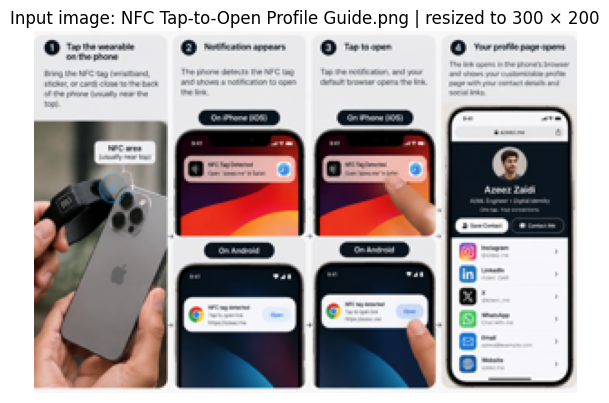

Original size: (1536, 1024)
Working size: (200, 300, 3)


In [2]:
uploaded = files.upload()
if not uploaded:
    raise ValueError("No image uploaded. Please run this cell again and choose an image.")

image_name = next(iter(uploaded))
image = Image.open(io.BytesIO(uploaded[image_name])).convert("RGB")

original_size = image.size
image.thumbnail((MAX_IMAGE_SIDE, MAX_IMAGE_SIDE))

image_np = np.asarray(image, dtype=np.uint8)
height, width, channels = image_np.shape

plt.figure(figsize=(7, 5))
plt.imshow(image_np)
plt.title(f"Input image: {image_name} | resized to {width} × {height}")
plt.axis("off")
plt.show()

print("Original size:", original_size)
print("Working size:", image_np.shape)

## 3. Prepare pixel features

RGB values are scaled to the range 0–1. If `SPATIAL_WEIGHT` is greater than zero, normalized X and Y coordinates are appended to the colour features. This can produce more spatially coherent regions, but changes the meaning of distance and should be reported in the project methodology.

In [ ]:
# Flatten image: one row per pixel
rgb_pixels = image_np.reshape(-1, 3).astype(np.float32) / 255.0

# Optional normalized spatial coordinates
yy, xx = np.mgrid[0:height, 0:width]
xy_pixels = np.column_stack([
    xx.ravel() / max(width - 1, 1),
    yy.ravel() / max(height - 1, 1)
]).astype(np.float32)

if SPATIAL_WEIGHT > 0:
    X = np.column_stack([rgb_pixels, SPATIAL_WEIGHT * xy_pixels])
else:
    X = rgb_pixels.copy()

print("Total pixels:", len(X))
print("Feature dimensions:", X.shape[1])

In [5]:

# Step 3: Prepare pixel features

# Convert image pixels into RGB values
rgb_pixels = image_np.reshape(-1, 3).astype(np.float32) / 255.0

# Generate pixel coordinates
yy, xx = np.mgrid[0:height, 0:width]

xy_pixels = np.column_stack([
    xx.ravel() / max(width - 1, 1),
    yy.ravel() / max(height - 1, 1)
]).astype(np.float32)

# Combine RGB and optional spatial features
if SPATIAL_WEIGHT > 0:
    X = np.column_stack([
        rgb_pixels,
        SPATIAL_WEIGHT * xy_pixels
    ])
else:
    X = rgb_pixels.copy()

print("Features prepared successfully!")
print("Total pixels:", len(X))
print("Feature dimensions:", X.shape[1])


Features prepared successfully!
Total pixels: 60000
Feature dimensions: 3


## 4. Evaluate candidate values of K

For a fair comparison, all metrics are calculated using the same random sample of pixels. Inertia is computed on that sample too, so the curves are comparable across K. Silhouette can be computationally expensive; reduce `METRIC_SAMPLE_SIZE` if this cell takes too long.

In [6]:
rng = np.random.default_rng(42)
sample_count = min(METRIC_SAMPLE_SIZE, len(X))
sample_indices = rng.choice(len(X), size=sample_count, replace=False)
X_sample = X[sample_indices]

results = []
sample_models = {}

for k in K_VALUES:
    print(f"Evaluating K={k} ...")
    model = KMeans(n_clusters=k, random_state=42, n_init=N_INIT)
    labels = model.fit_predict(X_sample)

    # Silhouette requires at least 2 labels and fewer labels than samples
    sil = silhouette_score(X_sample, labels)
    ch = calinski_harabasz_score(X_sample, labels)
    db = davies_bouldin_score(X_sample, labels)

    results.append({
        "K": k,
        "Inertia (WCSS)": model.inertia_,
        "Silhouette (higher is better)": sil,
        "Calinski-Harabasz (higher is better)": ch,
        "Davies-Bouldin (lower is better)": db
    })
    sample_models[k] = model

metrics_df = pd.DataFrame(results)
display(metrics_df.round(4))

Evaluating K=2 ...
Evaluating K=3 ...
Evaluating K=4 ...
Evaluating K=5 ...
Evaluating K=6 ...
Evaluating K=7 ...
Evaluating K=8 ...
Evaluating K=9 ...
Evaluating K=10 ...


,K,Inertia (WCSS),Silhouette (higher is better),Calinski-Harabasz (higher is better),Davies-Bouldin (lower is better)
0,2,447.4984,0.6521,15810.307617,0.4937
1,3,188.6253,0.6645,22179.484375,0.5380
2,4,136.0808,0.6710,21134.771484,0.6182
3,5,94.2760,0.6500,23429.189453,0.6163
4,6,75.5052,0.6177,23646.583984,0.6731
5,7,64.7876,0.6195,23098.708984,0.6966
6,8,56.3681,0.5768,22857.699219,0.7589
7,9,50.3604,0.5624,22456.433594,0.7681
8,10,45.5798,0.5214,22108.697266,0.7330


## 5. Visualize the quantitative criteria

Interpretation:
- **Elbow:** choose a K near the bend in the inertia curve; there is not always a single obvious elbow.
- **Silhouette:** measures how well-separated the clusters are; the maximum is a useful automatic candidate.
- **Calinski–Harabasz:** larger values indicate denser, better-separated clusters.
- **Davies–Bouldin:** smaller values indicate clusters that are more compact and separated.

Different metrics may recommend different K values. Discuss this disagreement in your PBL report.

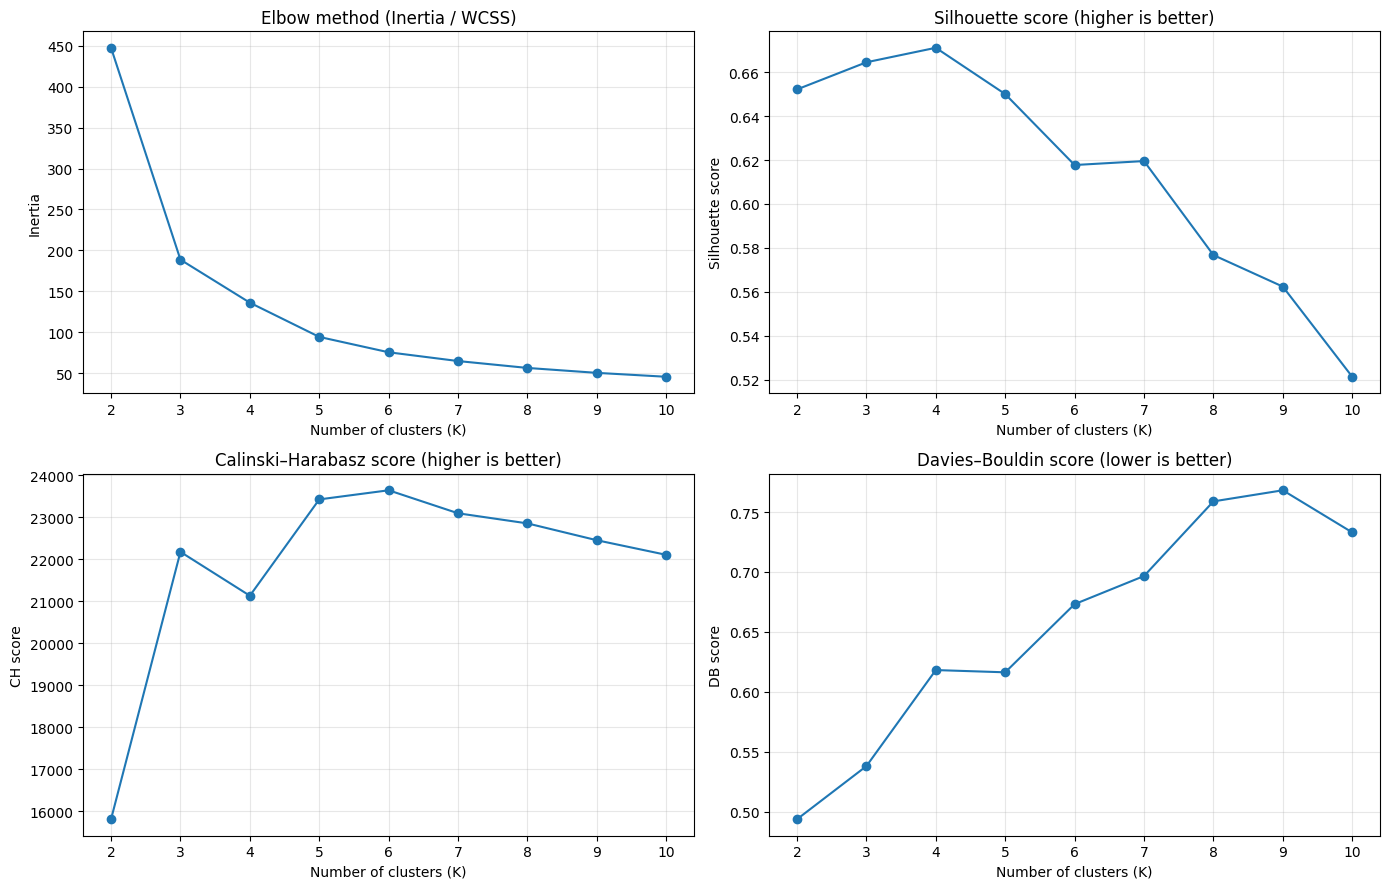

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(metrics_df["K"], metrics_df["Inertia (WCSS)"], marker="o")
axes[0, 0].set_title("Elbow method (Inertia / WCSS)")
axes[0, 0].set_xlabel("Number of clusters (K)")
axes[0, 0].set_ylabel("Inertia")
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(metrics_df["K"], metrics_df["Silhouette (higher is better)"], marker="o")
axes[0, 1].set_title("Silhouette score (higher is better)")
axes[0, 1].set_xlabel("Number of clusters (K)")
axes[0, 1].set_ylabel("Silhouette score")
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(metrics_df["K"], metrics_df["Calinski-Harabasz (higher is better)"], marker="o")
axes[1, 0].set_title("Calinski–Harabasz score (higher is better)")
axes[1, 0].set_xlabel("Number of clusters (K)")
axes[1, 0].set_ylabel("CH score")
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(metrics_df["K"], metrics_df["Davies-Bouldin (lower is better)"], marker="o")
axes[1, 1].set_title("Davies–Bouldin score (lower is better)")
axes[1, 1].set_xlabel("Number of clusters (K)")
axes[1, 1].set_ylabel("DB score")
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Automatically recommend K

The default recommendation is the K with the highest Silhouette score. The other metrics are reported alongside it as supporting evidence. This is a transparent, reproducible rule—not proof that the selected K is the only correct segmentation.

In [8]:
best_silhouette_row = metrics_df.loc[
    metrics_df["Silhouette (higher is better)"].idxmax()
]
best_ch_row = metrics_df.loc[
    metrics_df["Calinski-Harabasz (higher is better)"].idxmax()
]
best_db_row = metrics_df.loc[
    metrics_df["Davies-Bouldin (lower is better)"].idxmin()
]

selected_k = int(best_silhouette_row["K"])

print(f"Recommended K (maximum Silhouette): {selected_k}")
print(f"Maximum CH score occurs at K = {int(best_ch_row['K'])}")
print(f"Minimum DB score occurs at K = {int(best_db_row['K'])}")
print("\nSelected-K metric values:")
display(metrics_df[metrics_df["K"] == selected_k].round(4))

Recommended K (maximum Silhouette): 4
Maximum CH score occurs at K = 6
Minimum DB score occurs at K = 2

Selected-K metric values:


,K,Inertia (WCSS),Silhouette (higher is better),Calinski-Harabasz (higher is better),Davies-Bouldin (lower is better)
2,4,136.0808,0.671,21134.771484,0.6182


## 7. Fit the final model and generate the segmented image

The final model is trained on every pixel in the resized image using the selected K. Each pixel is replaced with the RGB value of its assigned cluster centre.

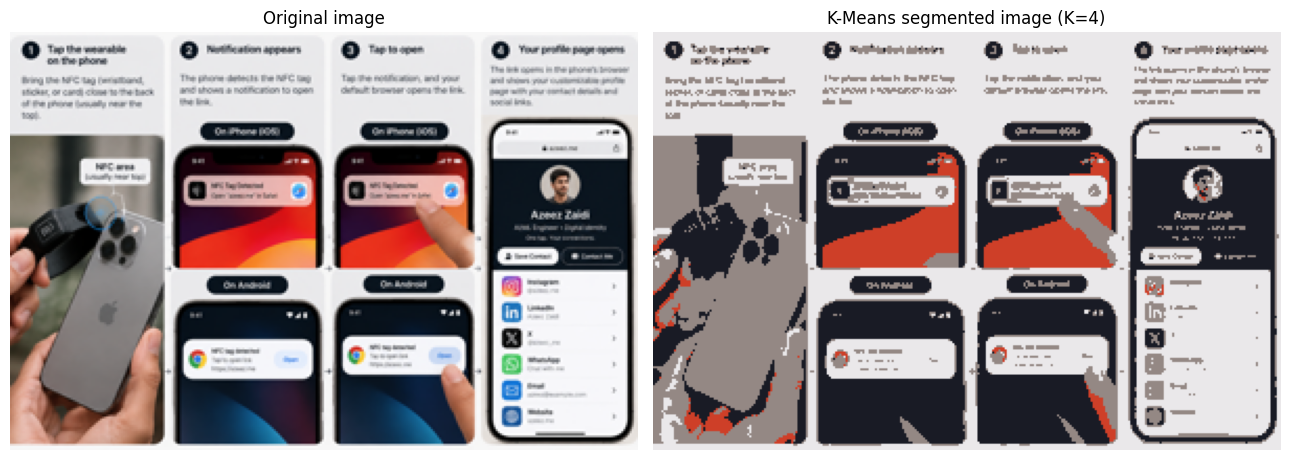

In [9]:
final_model = KMeans(
    n_clusters=selected_k,
    random_state=42,
    n_init=N_INIT
)
final_labels = final_model.fit_predict(X)

# The first three feature dimensions are RGB
cluster_centres_rgb = np.clip(final_model.cluster_centers_[:, :3], 0, 1)

segmented_pixels = cluster_centres_rgb[final_labels]
segmented_image = (segmented_pixels.reshape(height, width, 3) * 255).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(image_np)
axes[0].set_title("Original image")
axes[0].axis("off")

axes[1].imshow(segmented_image)
axes[1].set_title(f"K-Means segmented image (K={selected_k})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 8. Display individual cluster masks

Each panel shows the pixels assigned to one cluster. This helps explain which colours or regions the algorithm has grouped together.

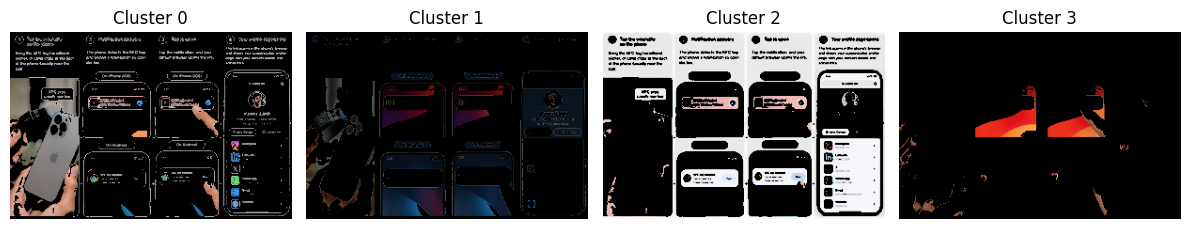

In [10]:
fig, axes = plt.subplots(1, selected_k, figsize=(3 * selected_k, 3))
if selected_k == 1:
    axes = [axes]

labels_image = final_labels.reshape(height, width)
for cluster_id, ax in enumerate(axes):
    mask = labels_image == cluster_id
    cluster_view = np.zeros_like(image_np)
    cluster_view[mask] = image_np[mask]
    ax.imshow(cluster_view)
    ax.set_title(f"Cluster {cluster_id}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 9. Save and download the segmented result

The output is saved as a PNG file.

In [11]:
output_name = "kmeans_segmented_image.png"
Image.fromarray(segmented_image).save(output_name)
files.download(output_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Project conclusion (complete after running)

Use your actual metric table and plots to write the conclusion. Suggested points:

1. State the image used and its resized dimensions.
2. State the range of K tested.
3. Report the K recommended by Silhouette, and the K preferred by CH and DB.
4. Explain whether the Elbow curve has a clear bend.
5. Describe the visual segmentation: which regions or colours were grouped together?
6. Discuss limitations: K-Means assumes clusters are reasonably compact in feature space, depends on initialization and feature scaling, and colour-only clustering may group distant pixels with similar colours.

**Important:** The best K depends on the image, feature representation, resize resolution, and evaluation sample. Do not write a fixed accuracy value: this is an unsupervised segmentation task and the notebook does not calculate ground-truth segmentation accuracy.